# Прогноз оттока клиентов — Часть 1
**Итоговый проект курса «Интеграция ИИ в разработку»** · автор части 1: Морозова Юлия

Постановка задачи, разведочный анализ данных, входы для архитектуры и контракт API.

| Блок |  | Что получаем |
|---|---|---|
| 1. Бизнес-постановка |  | Задача, пользователь, метрики, группы риска, экономика |
| 2. Качество данных |  | Список найденных проблем для человека, который делает валидацию |
| 3. EDA |  | Что влияет на отток |
| 4. Проверка осуществимости |  | Хватает ли классического ML (обоснование выбора архитектуры) |
| 5. Схема признаков и контракт |  | `feature_schema.csv` и `openapi.yaml` |

**Как запускать в Colab:** Runtime → Run all. Если файла с данными нет, ноутбук попросит загрузить `WA_Fn-UseC_-Telco-Customer-Churn.csv` (или `archive.zip`).

In [ ]:
import os, json, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "grid.alpha": 0.3})
SEED = 42

In [ ]:
FILE = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
path = next((p for p in [FILE, f"/content/{FILE}", f"data/{FILE}"] if os.path.exists(p)), None)

if path is None:
    try:
        from google.colab import files
        print(f"Файл {FILE} не найден. Загрузите его (или archive.zip):")
        uploaded = files.upload()
        name = next(iter(uploaded))
        if name.endswith(".zip"):
            with zipfile.ZipFile(name) as z:
                z.extractall(".")
            path = FILE
        else:
            path = name
    except ImportError:
        raise FileNotFoundError(f"Положите {FILE} рядом с ноутбуком")

df = pd.read_csv(path)
print("Файл:", path)
print("Размер:", df.shape)
df.head()

Файл WA_Fn-UseC_-Telco-Customer-Churn.csv не найден. Загрузите его (или archive.zip):


Saving archive.zip to archive.zip
Файл: WA_Fn-UseC_-Telco-Customer-Churn.csv
Размер: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Бизнес-постановка

**Контекст.** Телеком-оператор теряет часть клиентов. Отдел удержания может предложить уходящему клиенту скидку, смену тарифа или персональное предложение, но обзвонить всю базу нельзя: ресурс ограничен.

**Задача ML.** Бинарная классификация: по профилю и услугам клиента оценить вероятность ухода.

| | |
|---|---|
| **Пользователь** | Сотрудник отдела удержания (retention) |
| **Вход** | Профиль клиента: демография, срок обслуживания, подключённые услуги, тип контракта, способ оплаты, ежемесячный и накопленный платёж |
| **Выход** | Вероятность оттока (0–1) и группа риска: low / medium / high |
| **Решение пользователя** | low — ничего; medium — автоматическая рассылка с предложением; high — персональный звонок |
| **Горизонт** | По описанию датасета, целевая переменная `Churn` — клиент ушёл в последний месяц |

In [ ]:
churn_rate = (df["Churn"] == "Yes").mean()
print(f"Клиентов: {len(df)}")
print(f"Отток (Churn = Yes): {churn_rate:.1%}")
print(df["Churn"].value_counts().to_string())

Клиентов: 7043
Отток (Churn = Yes): 26.5%
Churn
No     5174
Yes    1869


**Следствие для метрик.** Классы несбалансированы (примерно 1 к 3), поэтому accuracy не подходит: модель, всегда отвечающая «не уйдёт», получит около 73%. Основные метрики: **ROC-AUC, PR-AUC, recall и precision по классу «уйдёт»**. Рабочий порог выбирается по экономике (раздел 4).

## 2. Качество данных: что нашли



In [ ]:
issues = {}

# 1. TotalCharges хранится строкой
df["TotalCharges_num"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
blank = df[df["TotalCharges_num"].isna()]
issues["TotalCharges: нечисловые (пустые) значения"] = len(blank)
print("TotalCharges dtype:", df["TotalCharges"].dtype)
print("Пустых/нечисловых TotalCharges:", len(blank), "| tenure у этих строк:", sorted(blank["tenure"].unique().tolist()))

# 2. Дубликаты
dup_cols = [c for c in df.columns if c not in ("customerID", "TotalCharges_num")]
n_dups = int(df.duplicated(subset=dup_cols).sum())
issues["Строки-дубли (без customerID)"] = n_dups
print("Уникальных customerID:", df["customerID"].nunique(), "из", len(df))
print("Дублей по всем признакам кроме ID:", n_dups)

# 3. Согласованность: 'No internet service' / 'No phone service' дублируют информацию
net_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
no_net = df["InternetService"] == "No"
consistent_net = bool((df.loc[no_net, net_cols] == "No internet service").all().all())
consistent_ph = bool((df.loc[df["PhoneService"] == "No", "MultipleLines"] == "No phone service").all())
print("Все 6 интернет-услуг = 'No internet service' при InternetService='No':", consistent_net, f"({no_net.sum()} клиентов)")
print("MultipleLines = 'No phone service' при PhoneService='No':", consistent_ph)

# 4. Разное кодирование бинарных признаков
print("SeniorCitizen значения:", sorted(df["SeniorCitizen"].unique().tolist()), "(числа), остальные бинарные — 'Yes'/'No'")

# 5. Мультиколлинеарность TotalCharges ~ tenure * MonthlyCharges
ok = df["TotalCharges_num"].notna()
corr = np.corrcoef(df.loc[ok, "TotalCharges_num"], df.loc[ok, "tenure"] * df.loc[ok, "MonthlyCharges"])[0, 1]
print(f"Корреляция TotalCharges и tenure*MonthlyCharges: {corr:.3f}")

# 6. Временная колонка
print("Колонок с датой/временем:", [c for c in df.columns if "date" in c.lower() or "time" in c.lower()] or "нет")

TotalCharges dtype: object
Пустых/нечисловых TotalCharges: 11 | tenure у этих строк: [0]
Уникальных customerID: 7043 из 7043
Дублей по всем признакам кроме ID: 22
Все 6 интернет-услуг = 'No internet service' при InternetService='No': True (1526 клиентов)
MultipleLines = 'No phone service' при PhoneService='No': True
SeniorCitizen значения: [0, 1] (числа), остальные бинарные — 'Yes'/'No'
Корреляция TotalCharges и tenure*MonthlyCharges: 1.000
Колонок с датой/временем: нет


**Что из этого важно дальше**

- `TotalCharges` приходит строкой, в 11 строках значение пустое; у всех этих клиентов `tenure = 0`, то есть они только что подключились. Логично заполнять нулём, но это решение нужно зафиксировать в валидации и в контракте.
- Дубли без учёта ID не обязательно ошибка: у разных клиентов профили могут совпасть. Это **риск**, а не доказанная ошибка;
- Значения `No internet service` и `No phone service` повторяют информацию из `InternetService` и `PhoneService`: информация избыточна, но не противоречива.
- `SeniorCitizen` закодирован числом, остальные бинарные признаки строками. В контракте это нужно описать явно, иначе возможен training-serving skew.
- `TotalCharges` почти полностью определяется `tenure × MonthlyCharges` (сильная корреляция): для линейных моделей это мультиколлинеарность.
- В данных нет даты: это **срез на один момент**. Значит, дрейф во времени на этих данных измерить нельзя, его придётся моделировать искусственно.

## 3. EDA: что связано с оттоком

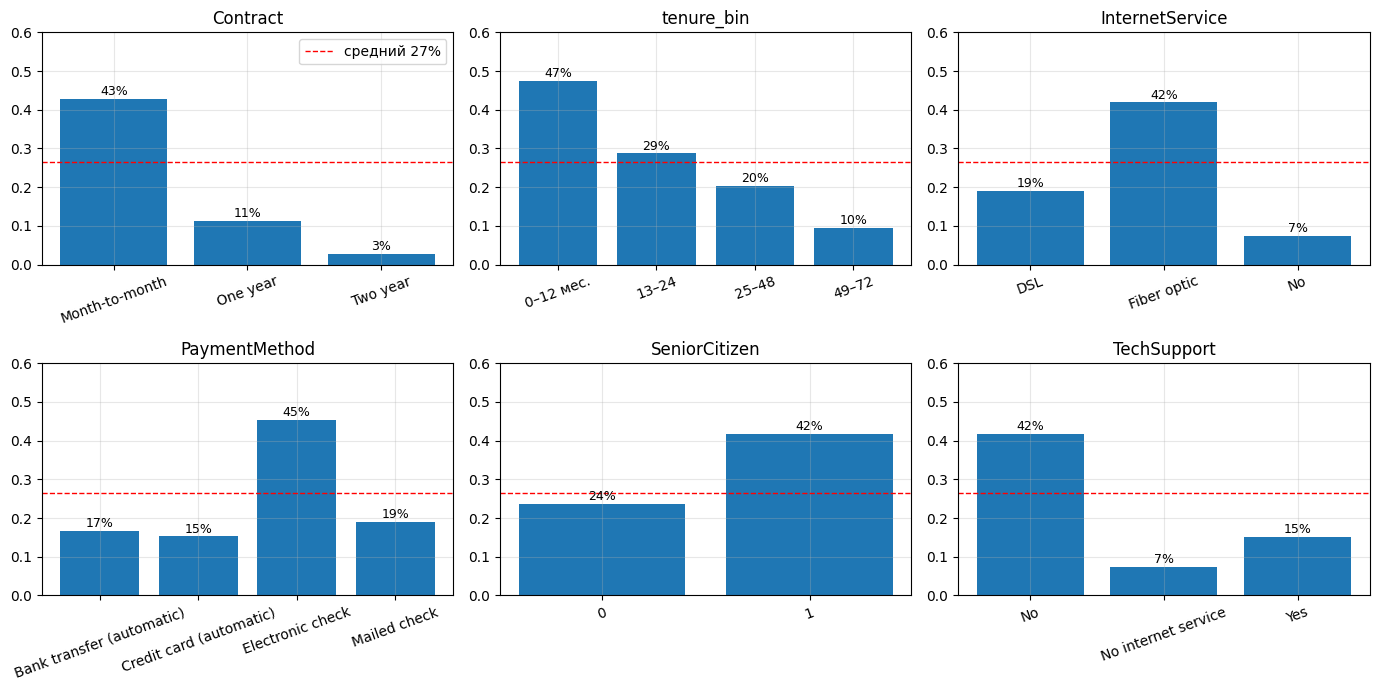

In [ ]:
def churn_by(col, data=df):
    t = (data.assign(is_churn=(data["Churn"] == "Yes"))
             .groupby(col, observed=True)["is_churn"].agg(["mean", "size"]))
    t.columns = ["churn_rate", "n"]
    return t

df["tenure_bin"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                          labels=["0–12 мес.", "13–24", "25–48", "49–72"])

segments = ["Contract", "tenure_bin", "InternetService", "PaymentMethod", "SeniorCitizen", "TechSupport"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), segments):
    t = churn_by(col)
    ax.bar(t.index.astype(str), t["churn_rate"])
    ax.axhline(churn_rate, color="red", ls="--", lw=1, label=f"средний {churn_rate:.0%}")
    ax.set_title(col)
    ax.set_ylim(0, 0.6)
    ax.tick_params(axis="x", rotation=20)
    for i, v in enumerate(t["churn_rate"]):
        ax.text(i, v + 0.01, f"{v:.0%}", ha="center", fontsize=9)
axes[0, 0].legend()
plt.tight_layout()
plt.savefig("eda_churn_drivers.png", dpi=130)
plt.show()

In [ ]:
summary = pd.concat({c: churn_by(c) for c in segments}, names=["признак", "значение"])
summary["churn_rate"] = summary["churn_rate"].map(lambda v: f"{v:.1%}")
summary

churn_rate     n
признак         значение                                  
Contract        Month-to-month                 42.7%  3875
                One year                       11.3%  1473
                Two year                        2.8%  1695
tenure_bin      0–12 мес.                      47.4%  2186
                13–24                          28.7%  1024
                25–48                          20.4%  1594
                49–72                           9.5%  2239
InternetService DSL                            19.0%  2421
                Fiber optic                    41.9%  3096
                No                              7.4%  1526
PaymentMethod   Bank transfer (automatic)      16.7%  1544
                Credit card (automatic)        15.2%  1522
                Electronic check               45.3%  2365
                Mailed check                   19.1%  1612
SeniorCitizen   0                              23.6%  5901
                1                              41.7%  1142
TechSupport     No                             41.6%  3473
                No internet service             7.4%  1526
                Yes                            15.2%  2044

In [ ]:
num = df[["tenure", "MonthlyCharges"]].join(df["Churn"])
print(num.groupby("Churn")[["tenure", "MonthlyCharges"]].agg(["mean", "median"]).round(1))

      tenure        MonthlyCharges       
        mean median           mean median
Churn                                    
No      37.6   38.0           61.3   64.4
Yes     18.0   10.0           74.4   79.6


**Выводы EDA**

- Тип контракта — самый сильный сигнал: при помесячной оплате отток около 43%, при двухлетнем контракте около 3%.
- Чем меньше срок обслуживания, тем выше риск: в первый год уходит почти каждый второй.
- Выше среднего отток у оптоволокна, оплаты электронным чеком и у клиентов-пенсионеров (`SeniorCitizen = 1`); без техподдержки он тоже выше.
- Последнее важно для этики и тестов на подгруппы: качество модели нужно проверять отдельно по пенсионерам.

## 4. Экономика и группы риска (ДЗ 1)

Порог «когда звонить клиенту» нельзя выбирать наугад: звонок стоит денег. Ниже простая модель. **Все параметры — допущения для демонстрации, а не данные компании**; их можно менять.

In [ ]:
HORIZON_MONTHS = 12        # допущение: считаем выручку клиента на год вперёд
DISCOUNT_SHARE = 0.10      # допущение: скидка 10% на горизонте
SUCCESS_RATE   = 0.30      # допущение: 30% клиентов, получивших предложение, остаются

monthly = df["MonthlyCharges"].mean()
value_lost = monthly * HORIZON_MONTHS                     # потеря при уходе
offer_cost = monthly * HORIZON_MONTHS * DISCOUNT_SHARE    # стоимость предложения

# Контакт выгоден, если p * SUCCESS_RATE * value_lost >= offer_cost
p_star = offer_cost / (SUCCESS_RATE * value_lost)
print(f"Средний MonthlyCharges: {monthly:.2f}")
print(f"Потеря при уходе за {HORIZON_MONTHS} мес.: {value_lost:.0f}; стоимость предложения: {offer_cost:.0f}")
print(f"Безубыточная вероятность оттока p* = {p_star:.2f}")

grid = pd.DataFrame(
    {f"успех {sr:.0%}": [d / sr for d in (0.05, 0.10, 0.15, 0.20)]
     for sr in (0.20, 0.30, 0.40, 0.50)},
    index=[f"скидка {d:.0%}" for d in (0.05, 0.10, 0.15, 0.20)])
print("\nЧувствительность p* к допущениям:")
print(grid.round(2))

Средний MonthlyCharges: 64.76
Потеря при уходе за 12 мес.: 777; стоимость предложения: 78
Безубыточная вероятность оттока p* = 0.33

Чувствительность p* к допущениям:
            успех 20%  успех 30%  успех 40%  успех 50%
скидка 5%        0.25       0.17       0.12        0.1
скидка 10%       0.50       0.33       0.25        0.2
скидка 15%       0.75       0.50       0.37        0.3
скидка 20%       1.00       0.67       0.50        0.4


In [ ]:
# Предварительные границы групп риска. Уточняются по реальной калибровке модели.
LOW_MAX  = 0.30
HIGH_MIN = 0.60

def risk_level(p: float) -> str:
    if p < LOW_MAX:
        return "low"
    if p < HIGH_MIN:
        return "medium"
    return "high"

print([ (p, risk_level(p)) for p in (0.05, 0.30, 0.45, 0.60, 0.90) ])

[(0.05, 'low'), (0.3, 'medium'), (0.45, 'medium'), (0.6, 'high'), (0.9, 'high')]


Граница между `low` и `medium` (0,30) близка к безубыточной вероятности при выбранных допущениях: от этого уровня предложение начинает окупаться. Граница `high` (0,60) отделяет клиентов, для которых оправдан дорогой канал (звонок). **Это стартовые значения**, а не результат подбора: после их нужно пересчитать по откалиброванным вероятностям модели.

## 5. Проверка осуществимости

Цель: убедиться, что классического ML достаточно и LLM/агент не нужны. Это **один запуск без подбора параметров**, а не эксперимент  — полноценные сравнения и MLflow сделает следующий участник.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score

X = df.drop(columns=["customerID", "Churn", "TotalCharges", "TotalCharges_num", "tenure_bin"]).copy()
X["TotalCharges"] = df["TotalCharges_num"].fillna(0.0)     # tenure = 0 -> 0
y = (df["Churn"] == "Yes").astype(int)

cat_cols = [c for c in X.columns if X[c].dtype == "object" or str(X[c].dtype) == "str"]
num_cols = [c for c in X.columns if c not in cat_cols]
print("Категориальных:", len(cat_cols), "| числовых:", len(num_cols), num_cols)

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols),
])
baseline = Pipeline([("prep", prep), ("clf", DummyClassifier(strategy="prior"))]).fit(X_tr, y_tr)
logreg   = Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=1000, random_state=SEED))]).fit(X_tr, y_tr)

for name, model in [("Dummy (всегда доля класса)", baseline), ("LogisticRegression", logreg)]:
    p = model.predict_proba(X_te)[:, 1]
    print(f"{name:28s} ROC-AUC = {roc_auc_score(y_te, p):.3f} | PR-AUC = {average_precision_score(y_te, p):.3f}")

Категориальных: 15 | числовых: 4 ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Dummy (всегда доля класса)   ROC-AUC = 0.500 | PR-AUC = 0.265
LogisticRegression           ROC-AUC = 0.842 | PR-AUC = 0.634


In [ ]:
p_te = logreg.predict_proba(X_te)[:, 1]
groups = pd.Series([risk_level(p) for p in p_te], index=y_te.index, name="risk")
check = (pd.DataFrame({"risk": groups, "churn": y_te})
           .groupby("risk")["churn"].agg(share_of_clients="size", actual_churn_rate="mean"))
check["share_of_clients"] = check["share_of_clients"] / len(y_te)
check = check.reindex(["low", "medium", "high"])
print("Как предварительные группы риска ложатся на тестовую выборку:")
print(check.round(3))

for thr in (LOW_MAX, HIGH_MIN):
    pred = (p_te >= thr).astype(int)
    print(f"порог {thr:.2f}: precision = {precision_score(y_te, pred):.2f}, recall = {recall_score(y_te, pred):.2f}")

Как предварительные группы риска ложатся на тестовую выборку:
        share_of_clients  actual_churn_rate
risk                                       
low                0.615              0.106
medium             0.237              0.395
high               0.148              0.718
порог 0.30: precision = 0.52, recall = 0.75
порог 0.60: precision = 0.72, recall = 0.40


**Вывод.** Простая логистическая регрессия сильно лучше случайного базового уровня, а группы риска действительно разделяют клиентов по фактическому оттоку. Для табличных данных такого размера классического ML достаточно; LLM и агенты усложнили бы систему без выигрыша. Это ориентир, а не итоговый результат: честные сравнения моделей — задача ДЗ 5.

Схема признаков (вход для контракта)

Имена признаков намеренно совпадают с именами колонок датасета: так между обучением и сервисом не возникает расхождения (training-serving skew).

In [ ]:
FEATURES = [c for c in X.columns]
rows = []
for c in FEATURES:
    s = X[c]
    if c in cat_cols:
        rows.append({"feature": c, "type": "string (enum)", "allowed": " | ".join(sorted(s.unique()))})
    elif c == "SeniorCitizen":
        rows.append({"feature": c, "type": "integer", "allowed": "0 | 1"})
    elif pd.api.types.is_integer_dtype(s):
        rows.append({"feature": c, "type": "integer", "allowed": f"{int(s.min())} … {int(s.max())}"})
    else:
        rows.append({"feature": c, "type": "number", "allowed": f"{s.min():.2f} … {s.max():.2f}"})
schema = pd.DataFrame(rows)
schema.to_csv("feature_schema.csv", index=False)
print(f"Признаков на входе сервиса: {len(schema)}")
schema

Признаков на входе сервиса: 19


,feature,type,allowed
0,gender,string (enum),Female | Male
1,SeniorCitizen,integer,0 | 1
2,Partner,string (enum),No | Yes
3,Dependents,string (enum),No | Yes
4,tenure,integer,0 … 72
5,PhoneService,string (enum),No | Yes
6,MultipleLines,string (enum),No | No phone service | Yes
7,InternetService,string (enum),DSL | Fiber optic | No
8,OnlineSecurity,string (enum),No | No internet service | Yes
9,OnlineBackup,string (enum),No | No internet service | Yes


## 7. Контракт API

В контракте два эндпоинта: `POST /v1/predict` и `GET /health`. Третий (`GET /v1/model/info`) появится как **MINOR-версия 1.1.0**: добавление эндпоинта не ломает существующих клиентов.

Целевая задержка (p95 < 200 мс) — это **цель SLA**, а не измерение.

In [ ]:
import yaml

def enum_of(col):
    return sorted(X[col].unique().tolist())

props = {}
for c in FEATURES:
    if c in cat_cols:
        props[c] = {"type": "string", "enum": enum_of(c)}
    elif c == "SeniorCitizen":
        props[c] = {"type": "integer", "enum": [0, 1], "description": "1 — пенсионер"}
    elif c == "tenure":
        props[c] = {"type": "integer", "minimum": 0, "maximum": 100, "description": "Месяцев обслуживания"}
    elif c == "MonthlyCharges":
        props[c] = {"type": "number", "minimum": 0, "description": "Ежемесячный платёж"}
    elif c == "TotalCharges":
        props[c] = {"type": "number", "minimum": 0, "description": "Накопленный платёж; 0 для клиентов с tenure = 0"}

error_ref = lambda desc: {"description": desc, "content": {"application/json": {"schema": {"$ref": "#/components/schemas/Error"}}}}

spec = {
    "openapi": "3.0.3",
    "info": {
        "title": "Churn Prediction API",
        "version": "1.0.0",
        "description": ("Оценивает вероятность ухода клиента телеком-оператора и относит его к группе риска. "
                        "Целевая задержка p95 < 200 мс (цель SLA, не измерение). "
                        "Версионирование: MAJOR — несовместимые изменения контракта, MINOR — новые эндпоинты/поля, PATCH — исправления."),
    },
    "servers": [{"url": "http://localhost:8000", "description": "Локальный запуск"}],
    "paths": {
        "/v1/predict": {"post": {
            "summary": "Прогноз оттока для одного клиента",
            "operationId": "predictChurn",
            "requestBody": {"required": True, "content": {"application/json": {
                "schema": {"$ref": "#/components/schemas/CustomerFeatures"}}}},
            "responses": {
                "200": {"description": "Прогноз", "content": {"application/json": {
                    "schema": {"$ref": "#/components/schemas/PredictionResponse"}}}},
                "422": error_ref("Нарушена схема входа: неизвестное значение, выход за диапазон, нет обязательного поля"),
                "503": error_ref("Модель не загружена"),
                "500": error_ref("Внутренняя ошибка"),
            }}},
        "/health": {"get": {
            "summary": "Проверка живости сервиса",
            "operationId": "health",
            "responses": {"200": {"description": "Сервис работает", "content": {"application/json": {
                "schema": {"$ref": "#/components/schemas/Health"}}}}}}},
    },
    "components": {"schemas": {
        "CustomerFeatures": {
            "type": "object",
            "required": FEATURES,
            "additionalProperties": False,
            "properties": {"customer_id": {"type": "string", "description": "Необязательный ID для трассировки; в модель не передаётся"}, **props},
        },
        "PredictionResponse": {
            "type": "object",
            "required": ["churn_probability", "risk_level", "model_version"],
            "properties": {
                "customer_id": {"type": "string"},
                "churn_probability": {"type": "number", "minimum": 0, "maximum": 1},
                "risk_level": {"type": "string", "enum": ["low", "medium", "high"],
                               "description": f"low < {LOW_MAX} <= medium < {HIGH_MIN} <= high (стартовые границы)"},
                "model_version": {"type": "string", "example": "churn-lr-0.1.0"},
            },
        },
        "Health": {"type": "object", "required": ["status"], "properties": {
            "status": {"type": "string", "enum": ["ok"]}}},
        "Error": {"type": "object", "required": ["detail"], "properties": {
            "detail": {"type": "string"}}},
    }},
}

with open("openapi.yaml", "w", encoding="utf-8") as f:
    yaml.safe_dump(spec, f, allow_unicode=True, sort_keys=False)
print("Сохранено: openapi.yaml,", len(FEATURES), "обязательных признаков")

Сохранено: openapi.yaml, 19 обязательных признаков


In [ ]:
%pip install -q openapi-spec-validator
from openapi_spec_validator import validate
validate(spec)
print("OpenAPI-спецификация валидна")

OpenAPI-спецификация валидна


In [ ]:
# Пример запроса и ответа на реальной строке датасета
row = X.iloc[[0]]
request = {"customer_id": df.loc[0, "customerID"], **{k: (v.item() if hasattr(v, "item") else v) for k, v in row.iloc[0].to_dict().items()}}
prob = float(logreg.predict_proba(row)[0, 1])
response = {"customer_id": request["customer_id"], "churn_probability": round(prob, 4),
            "risk_level": risk_level(prob), "model_version": "churn-lr-0.1.0"}

# проверка запроса по схеме: все признаки на месте и значения из допустимых
schema_props = spec["components"]["schemas"]["CustomerFeatures"]["properties"]
for k in FEATURES:
    assert k in request, f"нет поля {k}"
    if "enum" in schema_props[k]:
        assert request[k] in schema_props[k]["enum"], f"{k}={request[k]} не из enum"

print("POST /v1/predict\n", json.dumps(request, ensure_ascii=False, indent=2))
print("\n200 OK\n", json.dumps(response, ensure_ascii=False, indent=2))

POST /v1/predict
 {
  "customer_id": "7590-VHVEG",
  "gender": "Female",
  "SeniorCitizen": 0,
  "Partner": "Yes",
  "Dependents": "No",
  "tenure": 1,
  "PhoneService": "No",
  "MultipleLines": "No phone service",
  "InternetService": "DSL",
  "OnlineSecurity": "No",
  "OnlineBackup": "Yes",
  "DeviceProtection": "No",
  "TechSupport": "No",
  "StreamingTV": "No",
  "StreamingMovies": "No",
  "Contract": "Month-to-month",
  "PaperlessBilling": "Yes",
  "PaymentMethod": "Electronic check",
  "MonthlyCharges": 29.85,
  "TotalCharges": 29.85
}

200 OK
 {
  "customer_id": "7590-VHVEG",
  "churn_probability": 0.6137,
  "risk_level": "high",
  "model_version": "churn-lr-0.1.0"
}


## 8. Что передаём следующим участникам

| Кому | Что |
|---|---|
| (MLOps, MLflow, валидация) | Список проблем данных (раздел 2), метрики (ROC-AUC, PR-AUC, recall/precision по классу «уйдёт»), ориентир `LogisticRegression` из раздела 5, стартовые границы групп риска |
|  (тесты, FastAPI) | `openapi.yaml` и `feature_schema.csv`; подгруппа «пенсионеры» для тестов на подгруппы; ограничение: данные без даты |
|  (деплой, мониторинг) | Целевая задержка p95 < 200 мс; идея дрейфа: изменение доли помесячных контрактов или оптоволокна во входном потоке |

**Что в этом ноутбуке НЕ сделано намеренно:** подбор гиперпараметров, трекинг экспериментов, сравнение нескольких моделей, калибровка вероятностей

In [ ]:
# Необязательно: скачать результаты из Colab
try:
    from google.colab import files
    for f in ("openapi.yaml", "feature_schema.csv", "eda_churn_drivers.png"):
        files.download(f)
except ImportError:
    print("Не Colab: файлы лежат рядом с ноутбуком")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Часть 2. Эксперименты и валидация данных

В этой части проекта:
- проверяется схема и качество исходных данных;
- разбираются пропуски и совпадающие записи;
- фиксируются правила подготовки данных и разбиение выборки;
- проводятся не менее трёх экспериментов;
- сравниваются результаты и выбирается модель;
- сохраняются материалы для тестирования и дальнейшей интеграции.

Автор части: [ФИО].

Результаты предварительного эксперимента части 1 используются как
ориентир. Итоговые выводы этой части формируются после выполнения
проверок и сравнения моделей.

# Часть 2. Эксперименты и валидация данных

В этой части проекта:
- проверяется схема и качество исходных данных;
- разбираются пропуски и совпадающие записи;
- фиксируются правила подготовки данных и разбиение выборки;
- проводятся не менее трёх экспериментов;
- сравниваются результаты и выбирается модель;
- сохраняются материалы для тестирования и дальнейшей интеграции.

Автор части: [ФИО].

Результаты предварительного эксперимента части 1 используются как
ориентир. Итоговые выводы этой части формируются после выполнения
проверок и сравнения моделей.

In [1]:
from pathlib import Path
import hashlib
import platform

import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

SEED_PART2 = 42

DATA_FILENAME_PART2 = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

ARTIFACTS_PART2 = Path("/content/churn_part2_artifacts")
ARTIFACTS_PART2.mkdir(parents=True, exist_ok=True)

# Ищем исходный CSV независимо от переменных первой части.
candidate_paths_part2 = [
    Path(DATA_FILENAME_PART2),
    Path("/content") / DATA_FILENAME_PART2,
    Path("data") / DATA_FILENAME_PART2,
]

data_path_part2 = next(
    (path for path in candidate_paths_part2 if path.is_file()),
    None,
)

if data_path_part2 is None:
    from google.colab import files

    print("Загрузите исходный CSV-файл датасета.")
    uploaded_part2 = files.upload()

    csv_names_part2 = [
        name
        for name in uploaded_part2
        if name.lower().endswith(".csv")
    ]

    if len(csv_names_part2) != 1:
        raise ValueError(
            "Нужно загрузить ровно один CSV-файл с исходными данными."
        )

    data_path_part2 = Path(csv_names_part2[0])

# Эта таблица остаётся исходной: очистку будем делать в отдельной копии.
raw_part2 = pd.read_csv(data_path_part2)

data_sha256_part2 = hashlib.sha256(
    data_path_part2.read_bytes()
).hexdigest()

print("Файл:", data_path_part2.name)
print("Размер таблицы:", raw_part2.shape)
print("SHA256:", data_sha256_part2)

print("\nВерсии среды:")
print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)

print("\nКолонки:")
print(raw_part2.columns.tolist())

print("\nПервые 5 строк:")
display(raw_part2.head())

Файл: WA_Fn-UseC_-Telco-Customer-Churn.csv
Размер таблицы: (7043, 21)
SHA256: 88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a

Версии среды:
Python: 3.13.18
pandas: 2.2.3
NumPy: 2.4.6
scikit-learn: 1.6.1

Колонки:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Первые 5 строк:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
print("Типы данных:")
display(
    raw_part2.dtypes
    .astype(str)
    .rename("dtype")
    .to_frame()
)

if "Churn" not in raw_part2.columns:
    raise ValueError("В исходном CSV отсутствует целевая колонка Churn.")

print("\nРаспределение целевой переменной:")
display(
    raw_part2["Churn"]
    .value_counts(dropna=False)
    .rename_axis("Churn")
    .rename("Количество")
    .to_frame()
)

print("\nПримеры значений TotalCharges в исходном виде:")
if "TotalCharges" in raw_part2.columns:
    print(raw_part2["TotalCharges"].head(10).map(repr).to_string(index=False))
else:
    print("Колонка TotalCharges отсутствует.")

Типы данных:


,dtype
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object



Распределение целевой переменной:


,Количество
Churn,
No,5174
Yes,1869



Примеры значений TotalCharges в исходном виде:
  '29.85'
 '1889.5'
 '108.15'
'1840.75'
 '151.65'
  '820.5'
 '1949.4'
  '301.9'
'3046.05'
'3487.95'


## Валидация исходных данных

До обучения проверяем:
- соответствие набора колонок ожидаемой схеме;
- заполненность и уникальность идентификаторов;
- допустимые значения целевой переменной;
- пропуски, включая пустые строки и строки из пробелов;
- возможность преобразования числовых признаков в числа.

Исходная таблица raw_part2 не изменяется.
Обнаруженные проблемы и решения по их обработке фиксируются отдельно.

In [3]:
EXPECTED_COLUMNS_PART2 = [
    "customerID",
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "tenure",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod",
    "MonthlyCharges",
    "TotalCharges",
    "Churn",
]

missing_columns_part2 = sorted(
    set(EXPECTED_COLUMNS_PART2) - set(raw_part2.columns)
)

extra_columns_part2 = sorted(
    set(raw_part2.columns) - set(EXPECTED_COLUMNS_PART2)
)

duplicate_column_names_part2 = (
    raw_part2.columns[raw_part2.columns.duplicated()].tolist()
)

print("Отсутствующие колонки:", missing_columns_part2)
print("Лишние колонки:", extra_columns_part2)
print("Повторяющиеся имена колонок:", duplicate_column_names_part2)

if missing_columns_part2 or extra_columns_part2 or duplicate_column_names_part2:
    raise ValueError(
        "Схема исходной таблицы отличается от ожидаемой. "
        "Перед продолжением нужно разобрать расхождения."
    )

# Пропуски pandas и пустые строки считаем отдельно:
# эти две категории здесь не пересекаются.
missing_summary_part2 = pd.DataFrame(index=raw_part2.columns)

missing_summary_part2["NaN"] = raw_part2.isna().sum()

missing_summary_part2["Пустые строки / пробелы"] = pd.Series({
    column: int(
        raw_part2[column]
        .astype("string")
        .str.strip()
        .eq("")
        .fillna(False)
        .sum()
    )
    for column in raw_part2.columns
})

missing_summary_part2["Всего пропусков"] = (
    missing_summary_part2["NaN"]
    + missing_summary_part2["Пустые строки / пробелы"]
)

missing_summary_part2.index.name = "Колонка"

print("\nПроверка пропусков:")
display(missing_summary_part2)

id_missing_mask_part2 = (
    raw_part2["customerID"].isna()
    | raw_part2["customerID"]
        .astype("string")
        .str.strip()
        .eq("")
        .fillna(False)
)

# Число повторений после первого среди непустых ID.
duplicate_id_count_part2 = int(
    raw_part2.loc[
        ~id_missing_mask_part2, "customerID"
    ].duplicated().sum()
)

invalid_target_mask_part2 = ~raw_part2["Churn"].isin(["No", "Yes"])

basic_checks_part2 = pd.DataFrame([
    {
        "Проверка": "Отсутствующие обязательные колонки",
        "Нарушений": len(missing_columns_part2),
    },
    {
        "Проверка": "Лишние колонки",
        "Нарушений": len(extra_columns_part2),
    },
    {
        "Проверка": "Повторяющиеся имена колонок",
        "Нарушений": len(duplicate_column_names_part2),
    },
    {
        "Проверка": "Пустые customerID",
        "Нарушений": int(id_missing_mask_part2.sum()),
    },
    {
        "Проверка": "Повторы непустых customerID после первого",
        "Нарушений": duplicate_id_count_part2,
    },
    {
        "Проверка": "Churn вне допустимых значений No / Yes",
        "Нарушений": int(invalid_target_mask_part2.sum()),
    },
])

basic_checks_part2["Статус"] = np.where(
    basic_checks_part2["Нарушений"].eq(0),
    "PASS",
    "FAIL",
)

print("\nБазовые проверки:")
display(basic_checks_part2)

missing_summary_part2.to_csv(
    ARTIFACTS_PART2 / "missing_values_summary.csv",
    encoding="utf-8-sig",
)

basic_checks_part2.to_csv(
    ARTIFACTS_PART2 / "basic_data_checks.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nРезультаты проверок сохранены.")

Отсутствующие колонки: []
Лишние колонки: []
Повторяющиеся имена колонок: []

Проверка пропусков:


,NaN,Пустые строки / пробелы,Всего пропусков
Колонка,,,
customerID,0,0,0
gender,0,0,0
SeniorCitizen,0,0,0
Partner,0,0,0
Dependents,0,0,0
tenure,0,0,0
PhoneService,0,0,0
MultipleLines,0,0,0
InternetService,0,0,0



Базовые проверки:


,Проверка,Нарушений,Статус
0,Отсутствующие обязательные колонки,0,PASS
1,Лишние колонки,0,PASS
2,Повторяющиеся имена колонок,0,PASS
3,Пустые customerID,0,PASS
4,Повторы непустых customerID после первого,0,PASS
5,Churn вне допустимых значений No / Yes,0,PASS



Результаты проверок сохранены.


In [4]:
NUMERIC_COLUMNS_PART2 = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
]

numeric_converted_part2 = pd.DataFrame(index=raw_part2.index)
numeric_check_rows_part2 = []

for column in NUMERIC_COLUMNS_PART2:
    source_part2 = raw_part2[column]

    empty_mask_part2 = (
        source_part2.isna()
        | source_part2
            .astype("string")
            .str.strip()
            .eq("")
            .fillna(False)
    )

    converted_part2 = pd.to_numeric(
        source_part2,
        errors="coerce",
    )

    # Непустой исходный текст, который нельзя преобразовать в число.
    invalid_numeric_mask_part2 = (
        converted_part2.isna() & ~empty_mask_part2
    )

    numeric_converted_part2[column] = converted_part2

    numeric_check_rows_part2.append({
        "Колонка": column,
        "Исходных пропусков": int(empty_mask_part2.sum()),
        "Непустых нечисловых значений": int(
            invalid_numeric_mask_part2.sum()
        ),
        "Всего NaN после преобразования": int(
            converted_part2.isna().sum()
        ),
    })

numeric_checks_part2 = pd.DataFrame(numeric_check_rows_part2)

print("Проверка преобразования числовых признаков:")
display(numeric_checks_part2)

problem_totalcharges_mask_part2 = (
    numeric_converted_part2["TotalCharges"].isna()
)

problem_totalcharges_part2 = raw_part2.loc[
    problem_totalcharges_mask_part2,
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"],
].copy()

# repr позволяет увидеть пробел: ' ', а не визуально пустую ячейку.
problem_totalcharges_part2["TotalCharges_repr"] = (
    problem_totalcharges_part2["TotalCharges"].map(repr)
)

print("\nСтроки с пропущенным или нечисловым TotalCharges:")
display(problem_totalcharges_part2)

print(
    "\nКоличество проблемных строк:",
    int(problem_totalcharges_mask_part2.sum()),
)

print(
    "Количество среди них с tenure, отличным от 0:",
    int(
        numeric_converted_part2.loc[
            problem_totalcharges_mask_part2, "tenure"
        ].ne(0).sum()
    ),
)

numeric_checks_part2.to_csv(
    ARTIFACTS_PART2 / "numeric_conversion_checks.csv",
    index=False,
    encoding="utf-8-sig",
)

problem_totalcharges_part2.to_csv(
    ARTIFACTS_PART2 / "problem_totalcharges.csv",
    index=False,
    encoding="utf-8-sig",
)

Проверка преобразования числовых признаков:


,Колонка,Исходных пропусков,Непустых нечисловых значений,Всего NaN после преобразования
0,tenure,0,0,0
1,MonthlyCharges,0,0,0
2,TotalCharges,11,0,11



Строки с пропущенным или нечисловым TotalCharges:


Колонка,customerID,tenure,MonthlyCharges,TotalCharges,Churn,TotalCharges_repr
488,4472-LVYGI,0,52.55,,No,' '
753,3115-CZMZD,0,20.25,,No,' '
936,5709-LVOEQ,0,80.85,,No,' '
1082,4367-NUYAO,0,25.75,,No,' '
1340,1371-DWPAZ,0,56.05,,No,' '
3331,7644-OMVMY,0,19.85,,No,' '
3826,3213-VVOLG,0,25.35,,No,' '
4380,2520-SGTTA,0,20.00,,No,' '
5218,2923-ARZLG,0,19.70,,No,' '
6670,4075-WKNIU,0,73.35,,No,' '



Количество проблемных строк: 11
Количество среди них с tenure, отличным от 0: 0


### Допустимые значения и согласованность признаков

Проверяем словари категориальных признаков, диапазоны числовых
значений и согласованность зависимых услуг.

Отдельно различаем:
- полные повторные записи;
- совпадающие профили с одинаковой целевой меткой;
- совпадающие входные профили независимо от целевой метки.

Совпадение профилей при разных customerID не считается достаточным
основанием для удаления строк.

In [5]:
INTERNET_FEATURES_PART2 = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
]

ALLOWED_VALUES_PART2 = {
    "gender": ["Female", "Male"],
    "SeniorCitizen": [0, 1],
    "Partner": ["Yes", "No"],
    "Dependents": ["Yes", "No"],
    "PhoneService": ["Yes", "No"],
    "MultipleLines": ["Yes", "No", "No phone service"],
    "InternetService": ["DSL", "Fiber optic", "No"],
    **{
        column: ["Yes", "No", "No internet service"]
        for column in INTERNET_FEATURES_PART2
    },
    "Contract": ["Month-to-month", "One year", "Two year"],
    "PaperlessBilling": ["Yes", "No"],
    "PaymentMethod": [
        "Electronic check",
        "Mailed check",
        "Bank transfer (automatic)",
        "Credit card (automatic)",
    ],
    "Churn": ["No", "Yes"],
}

category_check_rows_part2 = []

for column, allowed_values in ALLOWED_VALUES_PART2.items():
    invalid_mask = ~raw_part2[column].isin(allowed_values)

    invalid_examples = (
        raw_part2.loc[invalid_mask, column]
        .map(repr)
        .unique()
        .tolist()
    )

    category_check_rows_part2.append({
        "Колонка": column,
        "Нарушений": int(invalid_mask.sum()),
        "Примеры": "; ".join(invalid_examples[:5]),
    })

category_checks_part2 = pd.DataFrame(category_check_rows_part2)

category_checks_part2["Статус"] = np.where(
    category_checks_part2["Нарушений"].eq(0),
    "PASS",
    "FAIL",
)

print("Проверка категорий:")
display(category_checks_part2)

range_check_rows_part2 = []

for column in NUMERIC_COLUMNS_PART2:
    values = numeric_converted_part2[column]

    # Пропуски уже посчитаны отдельно.
    # Здесь проверяем только присутствующие числовые значения.
    present_mask = values.notna()

    nonfinite_mask = present_mask & ~np.isfinite(values)
    negative_mask = present_mask & values.lt(0)

    range_check_rows_part2.extend([
        {
            "Проверка": f"{column}: бесконечные значения",
            "Нарушений": int(nonfinite_mask.sum()),
        },
        {
            "Проверка": f"{column}: отрицательные значения",
            "Нарушений": int(negative_mask.sum()),
        },
    ])

tenure_values_part2 = numeric_converted_part2["tenure"]
finite_tenure_mask_part2 = (
    tenure_values_part2.notna()
    & np.isfinite(tenure_values_part2)
)

range_check_rows_part2.append({
    "Проверка": "tenure: нецелое число месяцев",
    "Нарушений": int(
        tenure_values_part2.loc[finite_tenure_mask_part2]
        .mod(1)
        .ne(0)
        .sum()
    ),
})

range_checks_part2 = pd.DataFrame(range_check_rows_part2)

range_checks_part2["Статус"] = np.where(
    range_checks_part2["Нарушений"].eq(0),
    "PASS",
    "FAIL",
)

print("\nПроверка числовых диапазонов:")
display(range_checks_part2)

print("\nНаблюдаемые диапазоны — справочно, не правила валидации:")
display(
    numeric_converted_part2.agg(["min", "max"]).T
)

category_checks_part2.to_csv(
    ARTIFACTS_PART2 / "category_checks.csv",
    index=False,
    encoding="utf-8-sig",
)

range_checks_part2.to_csv(
    ARTIFACTS_PART2 / "numeric_range_checks.csv",
    index=False,
    encoding="utf-8-sig",
)

Проверка категорий:


,Колонка,Нарушений,Примеры,Статус
0,gender,0,,PASS
1,SeniorCitizen,0,,PASS
2,Partner,0,,PASS
3,Dependents,0,,PASS
4,PhoneService,0,,PASS
5,MultipleLines,0,,PASS
6,InternetService,0,,PASS
7,OnlineSecurity,0,,PASS
8,OnlineBackup,0,,PASS
9,DeviceProtection,0,,PASS



Проверка числовых диапазонов:


,Проверка,Нарушений,Статус
0,tenure: бесконечные значения,0,PASS
1,tenure: отрицательные значения,0,PASS
2,MonthlyCharges: бесконечные значения,0,PASS
3,MonthlyCharges: отрицательные значения,0,PASS
4,TotalCharges: бесконечные значения,0,PASS
5,TotalCharges: отрицательные значения,0,PASS
6,tenure: нецелое число месяцев,0,PASS



Наблюдаемые диапазоны — справочно, не правила валидации:


,min,max
tenure,0.00,72.00
MonthlyCharges,18.25,118.75
TotalCharges,18.80,8684.80


In [6]:
consistency_check_rows_part2 = []

no_internet_mask_part2 = raw_part2["InternetService"].eq("No")

for column in INTERNET_FEATURES_PART2:
    service_unavailable_mask = raw_part2[column].eq(
        "No internet service"
    )

    inconsistent_mask = (
        no_internet_mask_part2 != service_unavailable_mask
    )

    consistency_check_rows_part2.append({
        "Проверка": f"InternetService ↔ {column}",
        "Нарушений": int(inconsistent_mask.sum()),
    })

no_phone_mask_part2 = raw_part2["PhoneService"].eq("No")
no_phone_lines_mask_part2 = raw_part2["MultipleLines"].eq(
    "No phone service"
)

consistency_check_rows_part2.append({
    "Проверка": "PhoneService ↔ MultipleLines",
    "Нарушений": int(
        (no_phone_mask_part2 != no_phone_lines_mask_part2).sum()
    ),
})

consistency_checks_part2 = pd.DataFrame(
    consistency_check_rows_part2
)

consistency_checks_part2["Статус"] = np.where(
    consistency_checks_part2["Нарушений"].eq(0),
    "PASS",
    "FAIL",
)

display(consistency_checks_part2)

consistency_checks_part2.to_csv(
    ARTIFACTS_PART2 / "service_consistency_checks.csv",
    index=False,
    encoding="utf-8-sig",
)

,Проверка,Нарушений,Статус
0,InternetService ↔ OnlineSecurity,0,PASS
1,InternetService ↔ OnlineBackup,0,PASS
2,InternetService ↔ DeviceProtection,0,PASS
3,InternetService ↔ TechSupport,0,PASS
4,InternetService ↔ StreamingTV,0,PASS
5,InternetService ↔ StreamingMovies,0,PASS
6,PhoneService ↔ MultipleLines,0,PASS


In [7]:
FEATURE_COLUMNS_PART2 = [
    column
    for column in EXPECTED_COLUMNS_PART2
    if column not in ["customerID", "Churn"]
]

columns_without_id_part2 = [
    column
    for column in EXPECTED_COLUMNS_PART2
    if column != "customerID"
]

# Повторения после первой записи.
full_duplicate_count_part2 = int(
    raw_part2.duplicated().sum()
)

duplicate_with_target_count_part2 = int(
    raw_part2.duplicated(
        subset=columns_without_id_part2
    ).sum()
)

duplicate_profile_count_part2 = int(
    raw_part2.duplicated(
        subset=FEATURE_COLUMNS_PART2
    ).sum()
)

# Все строки, участвующие в совпадениях входных профилей.
matching_profile_mask_part2 = raw_part2.duplicated(
    subset=FEATURE_COLUMNS_PART2,
    keep=False,
)

matching_profile_rows_part2 = raw_part2.loc[
    matching_profile_mask_part2
].copy()

# Группировка выполняется без customerID и без Churn.
profile_groups_part2 = (
    raw_part2
    .groupby(
        FEATURE_COLUMNS_PART2,
        dropna=False,
        observed=True,
    )
    .agg(
        row_count=("customerID", "size"),
        target_variants=("Churn", "nunique"),
    )
    .reset_index()
)

conflicting_profile_groups_part2 = profile_groups_part2.loc[
    profile_groups_part2["target_variants"].gt(1)
].copy()

duplicate_summary_part2 = pd.DataFrame([
    {
        "Показатель": "Полные повторы, включая ID: после первой записи",
        "Количество": full_duplicate_count_part2,
    },
    {
        "Показатель": "Повторы без ID, включая Churn: после первой записи",
        "Количество": duplicate_with_target_count_part2,
    },
    {
        "Показатель": "Повторы только входных признаков: после первой записи",
        "Количество": duplicate_profile_count_part2,
    },
    {
        "Показатель": "Всего строк в совпадающих входных профилях",
        "Количество": int(matching_profile_mask_part2.sum()),
    },
    {
        "Показатель": "Группы одинаковых профилей с разными Churn",
        "Количество": len(conflicting_profile_groups_part2),
    },
])

print("Сводка совпадений:")
display(duplicate_summary_part2)

print("\nПримеры совпадающих профилей:")
display(
    matching_profile_rows_part2
    .sort_values(FEATURE_COLUMNS_PART2)
    .head(10)
)

duplicate_summary_part2.to_csv(
    ARTIFACTS_PART2 / "duplicate_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

matching_profile_rows_part2.to_csv(
    ARTIFACTS_PART2 / "matching_profile_rows.csv",
    index=False,
    encoding="utf-8-sig",
)

conflicting_profile_groups_part2.to_csv(
    ARTIFACTS_PART2 / "profiles_with_different_targets.csv",
    index=False,
    encoding="utf-8-sig",
)

Сводка совпадений:


,Показатель,Количество
0,"Полные повторы, включая ID: после первой записи",0
1,"Повторы без ID, включая Churn: после первой за...",22
2,Повторы только входных признаков: после первой...,40
3,Всего строк в совпадающих входных профилях,73
4,Группы одинаковых профилей с разными Churn,18



Примеры совпадающих профилей:


Колонка,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
3044,5692-FPTAH,Female,0,No,No,1,Yes,No,DSL,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,45.40,45.4,Yes
5480,2275-RBYQS,Female,0,No,No,1,Yes,No,DSL,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,45.40,45.4,No
684,8040-MNRTF,Female,0,No,No,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,No,Mailed check,71.10,71.1,No
4789,0511-JTEOY,Female,0,No,No,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,No,Mailed check,71.10,71.1,Yes
6491,9728-FTTVZ,Female,0,No,No,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,69.20,69.2,Yes
6764,7660-HDPJV,Female,0,No,No,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,69.20,69.2,Yes
4495,4702-IOQDC,Female,0,No,No,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.10,70.1,Yes
6267,0328-GRPMV,Female,0,No,No,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.10,70.1,Yes
3328,1640-PLFMP,Female,0,No,No,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.25,70.25,No
5662,3244-DCJWY,Female,0,No,No,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.25,70.25,Yes


### Решения по обработке данных

1. TotalCharges преобразуется в числовой формат.
2. Пустой TotalCharges при tenure = 0 заменяется нулём.
   Это учебное допущение: отсутствие накопленных начислений
   у нового клиента трактуется как нулевое значение.
3. Другие пропуски или нечисловые значения в числовых признаках
   должны останавливать подготовку данных.
4. Совпадающие профили при разных customerID сохраняются.
   Метки Churn не исправляются автоматически.
5. customerID исключается из признаков модели.

### Протокол сравнения моделей

Данные разделяются на train / validation / holdout
приблизительно в пропорции 60% / 20% / 20%.

- train — обучение моделей и подготовки признаков;
- validation — сравнение трёх конфигураций и выбор модели;
- holdout — итоговая оценка выбранного решения.

Разбиение стратифицировано по Churn, random_state = 42.

Для сопоставимости сохраняется состав 20%-го holdout из части 1.
Поскольку эта выборка уже использовалась в предварительном
эксперименте, она не считается новой полностью независимой
слепой проверкой.

Обучаемые преобразования признаков будут выполняться внутри
Pipeline с fit только на train.

In [8]:
# Не продолжаем подготовку, если предыдущие проверки нашли нарушения.
validation_tables_part2 = {
    "Базовые проверки": basic_checks_part2,
    "Категории": category_checks_part2,
    "Диапазоны": range_checks_part2,
    "Согласованность услуг": consistency_checks_part2,
}

for table_name, table in validation_tables_part2.items():
    if table["Статус"].eq("FAIL").any():
        raise ValueError(
            f"Есть нарушения в блоке «{table_name}». "
            "Сначала нужно их разобрать."
        )

# Повторное выполнение ячейки всегда начинается с исходных данных.
clean_part2 = raw_part2.copy(deep=True)

for column in NUMERIC_COLUMNS_PART2:
    clean_part2[column] = pd.to_numeric(
        clean_part2[column],
        errors="coerce",
    )

totalcharges_missing_part2 = clean_part2["TotalCharges"].isna()

allowed_totalcharges_missing_part2 = (
    totalcharges_missing_part2
    & clean_part2["tenure"].eq(0)
)

unexpected_totalcharges_missing_part2 = (
    totalcharges_missing_part2
    & ~allowed_totalcharges_missing_part2
)

if unexpected_totalcharges_missing_part2.any():
    raise ValueError(
        "Обнаружен отсутствующий TotalCharges при tenure != 0."
    )

# Допускаем заполнение только действительно пустых исходных значений.
source_totalcharges_empty_part2 = (
    raw_part2["TotalCharges"].isna()
    | raw_part2["TotalCharges"]
        .astype("string")
        .str.strip()
        .eq("")
        .fillna(False)
)

if (
    allowed_totalcharges_missing_part2
    & ~source_totalcharges_empty_part2
).any():
    raise ValueError(
        "Найден непустой нечисловой TotalCharges. "
        "Его нельзя автоматически заменить нулём."
    )

clean_part2.loc[
    allowed_totalcharges_missing_part2,
    "TotalCharges",
] = 0.0

# После обработки не должно остаться пропусков или бесконечностей.
if clean_part2[NUMERIC_COLUMNS_PART2].isna().any().any():
    raise ValueError("После обработки остались числовые пропуски.")

if not np.isfinite(
    clean_part2[NUMERIC_COLUMNS_PART2].to_numpy(dtype=float)
).all():
    raise ValueError("После обработки найдены бесконечные значения.")

X_part2 = clean_part2[FEATURE_COLUMNS_PART2].copy()

y_part2 = (
    clean_part2["Churn"]
    .map({"No": 0, "Yes": 1})
    .astype(int)
)

assert "customerID" not in X_part2.columns
assert "Churn" not in X_part2.columns
assert X_part2.shape[1] == 19
assert len(clean_part2) == len(raw_part2)

cleaning_decisions_part2 = pd.DataFrame([
    {
        "Действие": "Преобразование TotalCharges в числовой формат",
        "Количество": len(clean_part2),
        "Комментарий": "Исходная таблица не изменяется",
    },
    {
        "Действие": "Заполнение пустого TotalCharges нулём",
        "Количество": int(allowed_totalcharges_missing_part2.sum()),
        "Комментарий": "Только при tenure = 0; учебное допущение",
    },
    {
        "Действие": "Удаление строк",
        "Количество": 0,
        "Комментарий": "Совпадающие профили разных клиентов сохранены",
    },
])

display(cleaning_decisions_part2)

print("\nРазмер X:", X_part2.shape)
print("Размер y:", y_part2.shape)
print("Пропусков в X:", int(X_part2.isna().sum().sum()))
print("Положительный класс: 1 — клиент ушёл")

cleaning_decisions_part2.to_csv(
    ARTIFACTS_PART2 / "cleaning_decisions.csv",
    index=False,
    encoding="utf-8-sig",
)

,Действие,Количество,Комментарий
0,Преобразование TotalCharges в числовой формат,7043,Исходная таблица не изменяется
1,Заполнение пустого TotalCharges нулём,11,Только при tenure = 0; учебное допущение
2,Удаление строк,0,Совпадающие профили разных клиентов сохранены



Размер X: (7043, 19)
Размер y: (7043,)
Пропусков в X: 0
Положительный класс: 1 — клиент ушёл


In [9]:
from sklearn.model_selection import train_test_split

# Повторяем исходное выделение holdout из части 1.
dev_indices_part2, holdout_indices_part2 = train_test_split(
    X_part2.index.to_numpy(),
    test_size=0.20,
    stratify=y_part2,
    random_state=SEED_PART2,
)

# 25% от оставшихся 80% дают примерно 20% всех данных.
train_indices_part2, val_indices_part2 = train_test_split(
    dev_indices_part2,
    test_size=0.25,
    stratify=y_part2.loc[dev_indices_part2],
    random_state=SEED_PART2,
)

split_indices_part2 = {
    "train": train_indices_part2,
    "validation": val_indices_part2,
    "holdout": holdout_indices_part2,
}

# Проверяем, что строки не пересекаются и ничего не потеряно.
train_set_part2 = set(train_indices_part2)
val_set_part2 = set(val_indices_part2)
holdout_set_part2 = set(holdout_indices_part2)

assert train_set_part2.isdisjoint(val_set_part2)
assert train_set_part2.isdisjoint(holdout_set_part2)
assert val_set_part2.isdisjoint(holdout_set_part2)

assert (
    train_set_part2 | val_set_part2 | holdout_set_part2
) == set(X_part2.index)

X_train_part2 = X_part2.loc[train_indices_part2].copy()
X_val_part2 = X_part2.loc[val_indices_part2].copy()
X_holdout_part2 = X_part2.loc[holdout_indices_part2].copy()

y_train_part2 = y_part2.loc[train_indices_part2].copy()
y_val_part2 = y_part2.loc[val_indices_part2].copy()
y_holdout_part2 = y_part2.loc[holdout_indices_part2].copy()

split_summary_part2 = pd.DataFrame([
    {
        "Выборка": name,
        "Клиентов": len(indices),
        "Доля всех данных": len(indices) / len(X_part2),
        "Клиентов с оттоком": int(y_part2.loc[indices].sum()),
        "Доля оттока": float(y_part2.loc[indices].mean()),
    }
    for name, indices in split_indices_part2.items()
])

print("Состав выборок:")
display(split_summary_part2)

# Сохраняем принадлежность каждой строки к выборке.
split_manifest_part2 = pd.concat(
    [
        pd.DataFrame({
            "row_index": indices,
            "customerID": raw_part2.loc[
                indices, "customerID"
            ].to_numpy(),
            "split": name,
        })
        for name, indices in split_indices_part2.items()
    ],
    ignore_index=True,
)

split_summary_part2.to_csv(
    ARTIFACTS_PART2 / "split_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

split_manifest_part2.to_csv(
    ARTIFACTS_PART2 / "split_manifest.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nРазбиение сохранено. Пересечений строк между выборками нет.")

Состав выборок:


,Выборка,Клиентов,Доля всех данных,Клиентов с оттоком,Доля оттока
0,train,4225,0.599886,1121,0.265325
1,validation,1409,0.200057,374,0.265436
2,holdout,1409,0.200057,374,0.265436



Разбиение сохранено. Пересечений строк между выборками нет.


In [10]:
# Общий номер для каждого уникального входного профиля.
# Это только диагностика совпадений, не признак для модели.
profile_id_part2 = (
    clean_part2
    .groupby(
        FEATURE_COLUMNS_PART2,
        dropna=False,
        observed=True,
        sort=False,
    )
    .ngroup()
)

overlap_rows_part2 = []

for reference_name, checked_name in [
    ("train", "validation"),
    ("train", "holdout"),
    ("validation", "holdout"),
]:
    reference_indices = split_indices_part2[reference_name]
    checked_indices = split_indices_part2[checked_name]

    reference_profiles = set(
        profile_id_part2.loc[reference_indices]
    )

    matching_mask = profile_id_part2.loc[
        checked_indices
    ].isin(reference_profiles)

    overlap_rows_part2.append({
        "С чем сравниваем": reference_name,
        "Проверяемая выборка": checked_name,
        "Строк с совпадающим профилем": int(matching_mask.sum()),
        "Доля проверяемой выборки": float(matching_mask.mean()),
    })

profile_overlap_part2 = pd.DataFrame(overlap_rows_part2)

display(profile_overlap_part2)

profile_overlap_part2.to_csv(
    ARTIFACTS_PART2 / "profile_overlap.csv",
    index=False,
    encoding="utf-8-sig",
)

,С чем сравниваем,Проверяемая выборка,Строк с совпадающим профилем,Доля проверяемой выборки
0,train,validation,10,0.007097
1,train,holdout,13,0.009226
2,validation,holdout,1,0.000710


## Эксперименты

Сравниваются три фиксированные конфигурации:
1. Логистическая регрессия.
2. Случайный лес.
3. Градиентный бустинг.

Дополнительно используется DummyClassifier как точка отсчёта.

Основная метрика выбора — Average Precision (AP) на validation.
В части 1 результат average_precision_score обозначался как PR-AUC;
здесь используется точное название AP.

Дополнительные метрики:
- ROC-AUC;
- precision, recall и F1 при общем пороге 0,50;
- время обучения.

Категориальные признаки кодируются OneHotEncoder.
Числовые признаки масштабируются StandardScaler.
Все обучаемые преобразования находятся внутри Pipeline
и обучаются только на train.

Для каждого запуска создаётся отдельный pipeline.
Подбор гиперпараметров на данном этапе не проводится.

In [11]:
import json
import time

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
)

# SeniorCitizen остаётся числовым бинарным признаком.
NUMERIC_FEATURES_PART2 = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
]

CATEGORICAL_FEATURES_PART2 = [
    column
    for column in FEATURE_COLUMNS_PART2
    if column not in NUMERIC_FEATURES_PART2
]

assert set(NUMERIC_FEATURES_PART2).isdisjoint(
    CATEGORICAL_FEATURES_PART2
)

assert (
    set(NUMERIC_FEATURES_PART2)
    | set(CATEGORICAL_FEATURES_PART2)
) == set(X_part2.columns)


def make_pipeline_part2(classifier):
    """Создаёт новый независимый pipeline для одного запуска."""
    preprocessing = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False,
                ),
                CATEGORICAL_FEATURES_PART2,
            ),
            (
                "numeric",
                StandardScaler(),
                NUMERIC_FEATURES_PART2,
            ),
        ],
        remainder="drop",
    )

    return Pipeline([
        ("preprocessing", preprocessing),
        ("classifier", clone(classifier)),
    ])


print(
    f"Числовые признаки ({len(NUMERIC_FEATURES_PART2)}):",
    NUMERIC_FEATURES_PART2,
)

print(
    f"\nКатегориальные признаки ({len(CATEGORICAL_FEATURES_PART2)}):",
    CATEGORICAL_FEATURES_PART2,
)

Числовые признаки (4): ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Категориальные признаки (15): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [13]:
THRESHOLD_PART2 = 0.50

# Не стираем результаты, если эту ячейку выполнили повторно.
if "experiment_results_part2" not in globals():
    experiment_results_part2 = {}

if "trained_models_part2" not in globals():
    trained_models_part2 = {}

if "validation_probabilities_part2" not in globals():
    validation_probabilities_part2 = {}

if "experiment_parameters_part2" not in globals():
    experiment_parameters_part2 = {}


def calculate_metrics_part2(y_true, probabilities, threshold=0.50):
    probabilities = np.asarray(probabilities)

    if not np.isfinite(probabilities).all():
        raise ValueError("Прогноз содержит NaN или бесконечность.")

    if ((probabilities < 0) | (probabilities > 1)).any():
        raise ValueError("Вероятности находятся вне диапазона [0, 1].")

    predicted_labels = (probabilities >= threshold).astype(int)

    return {
        "AP": float(
            average_precision_score(y_true, probabilities)
        ),
        "ROC_AUC": float(
            roc_auc_score(y_true, probabilities)
        ),
        "precision": float(
            precision_score(
                y_true,
                predicted_labels,
                zero_division=0,
            )
        ),
        "recall": float(
            recall_score(
                y_true,
                predicted_labels,
                zero_division=0,
            )
        ),
        "F1": float(
            f1_score(
                y_true,
                predicted_labels,
                zero_division=0,
            )
        ),
    }


def run_experiment_part2(run_id, classifier):
    pipeline = make_pipeline_part2(classifier)

    started_at = time.perf_counter()

    pipeline.fit(
        X_train_part2,
        y_train_part2,
    )

    fit_seconds = time.perf_counter() - started_at

    classes = pipeline.named_steps["classifier"].classes_
    positive_columns = np.flatnonzero(classes == 1)

    if len(positive_columns) != 1:
        raise ValueError(
            f"Не удалось определить положительный класс: {classes}"
        )

    probabilities = pipeline.predict_proba(
        X_val_part2
    )[:, positive_columns[0]]

    metrics = calculate_metrics_part2(
        y_val_part2,
        probabilities,
        threshold=THRESHOLD_PART2,
    )

    experiment_results_part2[run_id] = {
        "run_id": run_id,
        "model": type(classifier).__name__,
        "dataset": "validation",
        "threshold": THRESHOLD_PART2,
        **metrics,
        "fit_seconds": fit_seconds,
    }

    trained_models_part2[run_id] = pipeline
    validation_probabilities_part2[run_id] = probabilities

    experiment_parameters_part2[run_id] = {
        "classifier_parameters": classifier.get_params(deep=False),
        "data_sha256": data_sha256_part2,
        "split_seed": SEED_PART2,
        "train_size": len(X_train_part2),
        "validation_size": len(X_val_part2),
        "numeric_features": NUMERIC_FEATURES_PART2,
        "categorical_features": CATEGORICAL_FEATURES_PART2,
    }

    results_table = (
        pd.DataFrame(experiment_results_part2.values())
        .sort_values("run_id")
        .reset_index(drop=True)
    )

    results_table.to_csv(
        ARTIFACTS_PART2 / "experiments_validation.csv",
        index=False,
        encoding="utf-8-sig",
    )

    with open(
        ARTIFACTS_PART2 / "experiment_parameters.json",
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(
            experiment_parameters_part2,
            file,
            ensure_ascii=False,
            indent=2,
        )

    print(f"Завершён запуск: {run_id}")
    display(results_table.round(5))

    return pipeline

In [14]:
dummy_pipeline_part2 = run_experiment_part2(
    run_id="E0_Dummy",
    classifier=DummyClassifier(
        strategy="prior",
    ),
)

logistic_pipeline_part2 = run_experiment_part2(
    run_id="E1_LogisticRegression",
    classifier=LogisticRegression(
        C=1.0,
        max_iter=2000,
        solver="lbfgs",
        random_state=SEED_PART2,
    ),
)

print("\nРазмер обучающей матрицы после преобразований:")

transformed_train_part2 = (
    logistic_pipeline_part2
    .named_steps["preprocessing"]
    .transform(X_train_part2)
)

print(transformed_train_part2.shape)

Завершён запуск: E0_Dummy


,run_id,model,dataset,threshold,AP,ROC_AUC,precision,recall,F1,fit_seconds
0,E0_Dummy,DummyClassifier,validation,0.5,0.26544,0.5,0.0,0.0,0.0,0.03906


Завершён запуск: E1_LogisticRegression


,run_id,model,dataset,threshold,AP,ROC_AUC,precision,recall,F1,fit_seconds
0,E0_Dummy,DummyClassifier,validation,0.5,0.26544,0.50000,0.00000,0.00000,0.00000,0.03906
1,E1_LogisticRegression,LogisticRegression,validation,0.5,0.64240,0.83605,0.65789,0.53476,0.58997,0.17272



Размер обучающей матрицы после преобразований:
(4225, 45)


### Эксперимент № 2. Случайный лес

Проверяем, улучшает ли выбранная конфигурация случайного леса
качество по сравнению с логистической регрессией.

Фиксируем:
- n_estimators = 300;
- max_depth = 10;
- min_samples_leaf = 5;
- random_state = 42.

### Эксперимент № 3. Градиентный бустинг

Проверяем качество выбранной конфигурации градиентного бустинга.

Фиксируем:
- n_estimators = 200;
- learning_rate = 0.05;
- max_depth = 2;
- random_state = 42.

Обе модели используют то же разбиение и общий процесс подготовки
признаков. Масштабирование числовых признаков сохраняется внутри
общего pipeline для единообразия реализации.

Это сравнение фиксированных конфигураций, а не поиск оптимальных
гиперпараметров. Выбор выполняется по AP на validation.

In [15]:
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
)

forest_pipeline_part2 = run_experiment_part2(
    run_id="E2_RandomForest",
    classifier=RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        min_samples_leaf=5,
        random_state=SEED_PART2,
        n_jobs=-1,
    ),
)

Завершён запуск: E2_RandomForest


,run_id,model,dataset,threshold,AP,ROC_AUC,precision,recall,F1,fit_seconds
0,E0_Dummy,DummyClassifier,validation,0.5,0.26544,0.50000,0.00000,0.00000,0.00000,0.03906
1,E1_LogisticRegression,LogisticRegression,validation,0.5,0.64240,0.83605,0.65789,0.53476,0.58997,0.17272
2,E2_RandomForest,RandomForestClassifier,validation,0.5,0.63860,0.83669,0.65543,0.46791,0.54602,1.58264


In [16]:
boosting_pipeline_part2 = run_experiment_part2(
    run_id="E3_GradientBoosting",
    classifier=GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=2,
        random_state=SEED_PART2,
    ),
)

Завершён запуск: E3_GradientBoosting


,run_id,model,dataset,threshold,AP,ROC_AUC,precision,recall,F1,fit_seconds
0,E0_Dummy,DummyClassifier,validation,0.5,0.26544,0.50000,0.00000,0.00000,0.00000,0.03906
1,E1_LogisticRegression,LogisticRegression,validation,0.5,0.64240,0.83605,0.65789,0.53476,0.58997,0.17272
2,E2_RandomForest,RandomForestClassifier,validation,0.5,0.63860,0.83669,0.65543,0.46791,0.54602,1.58264
3,E3_GradientBoosting,GradientBoostingClassifier,validation,0.5,0.64397,0.83853,0.66431,0.50267,0.57230,1.83954


In [17]:
EXPECTED_RUNS_PART2 = [
    "E0_Dummy",
    "E1_LogisticRegression",
    "E2_RandomForest",
    "E3_GradientBoosting",
]

missing_runs_part2 = [
    run_id
    for run_id in EXPECTED_RUNS_PART2
    if run_id not in experiment_results_part2
]

if missing_runs_part2:
    raise ValueError(
        f"Сначала выполните недостающие запуски: {missing_runs_part2}"
    )

comparison_part2 = pd.DataFrame([
    experiment_results_part2[run_id]
    for run_id in EXPECTED_RUNS_PART2
])

baseline_ap_part2 = experiment_results_part2[
    "E1_LogisticRegression"
]["AP"]

comparison_part2["AP_delta_vs_logistic"] = (
    comparison_part2["AP"] - baseline_ap_part2
)

print("Сравнение на validation:")
display(
    comparison_part2[
        [
            "run_id",
            "AP",
            "ROC_AUC",
            "precision",
            "recall",
            "F1",
            "AP_delta_vs_logistic",
            "fit_seconds",
        ]
    ].round(6)
)

# Dummy не участвует в выборе итоговой модели.
model_candidates_part2 = comparison_part2.loc[
    comparison_part2["run_id"].ne("E0_Dummy")
].copy()

# Основной критерий — максимум AP.
# При точном равенстве выбираем по run_id для воспроизводимости.
ranking_part2 = model_candidates_part2.sort_values(
    ["AP", "run_id"],
    ascending=[False, True],
).reset_index(drop=True)

selected_run_id_part2 = ranking_part2.loc[0, "run_id"]
selected_model_part2 = trained_models_part2[
    selected_run_id_part2
]

print("\nВыбранный запуск:", selected_run_id_part2)
print(
    "Validation AP:",
    f"{ranking_part2.loc[0, 'AP']:.6f}",
)

ap_gap_part2 = (
    ranking_part2.loc[0, "AP"]
    - ranking_part2.loc[1, "AP"]
)

print(
    "Разница AP между первым и вторым местом:",
    f"{ap_gap_part2:.6f}",
)

print(
    "\nВыбор относится к этим конфигурациям и этому разбиению. "
    "Статистическая значимость различий пока не проверялась."
)

comparison_part2.to_csv(
    ARTIFACTS_PART2 / "experiments_comparison.csv",
    index=False,
    encoding="utf-8-sig",
)

selection_part2 = {
    "selected_run_id": selected_run_id_part2,
    "selection_dataset": "validation",
    "selection_metric": "average_precision",
    "selected_validation_AP": float(ranking_part2.loc[0, "AP"]),
    "AP_gap_to_second_place": float(ap_gap_part2),
    "classification_threshold": THRESHOLD_PART2,
    "hyperparameter_search_performed": False,
    "statistical_significance_test_performed": False,
}

with open(
    ARTIFACTS_PART2 / "model_selection.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        selection_part2,
        file,
        ensure_ascii=False,
        indent=2,
    )

Сравнение на validation:


,run_id,AP,ROC_AUC,precision,recall,F1,AP_delta_vs_logistic,fit_seconds
0,E0_Dummy,0.265436,0.500000,0.000000,0.000000,0.000000,-0.376961,0.039057
1,E1_LogisticRegression,0.642397,0.836047,0.657895,0.534759,0.589971,0.000000,0.172716
2,E2_RandomForest,0.638603,0.836688,0.655431,0.467914,0.546022,-0.003794,1.582639
3,E3_GradientBoosting,0.643972,0.838531,0.664311,0.502674,0.572298,0.001575,1.839537



Выбранный запуск: E3_GradientBoosting
Validation AP: 0.643972
Разница AP между первым и вторым местом: 0.001575

Выбор относится к этим конфигурациям и этому разбиению. Статистическая значимость различий пока не проверялась.


### Выводы по экспериментам

На одинаковом разбиении выполнены три основных эксперимента.
Критерий выбора — Average Precision (AP) на validation.

1. Logistic Regression:
   AP = 0,642397, ROC-AUC = 0,836047.
   При пороге 0,50 модель получила наибольшие recall = 0,534759
   и F1 = 0,589971 среди трёх конфигураций.

2. Random Forest:
   AP = 0,638603, ROC-AUC = 0,836688.
   По сравнению с логистической регрессией AP снизился на 0,003794.
   При выбранных параметрах усложнение модели не улучшило
   основной критерий качества.

3. Gradient Boosting:
   AP = 0,643972, ROC-AUC = 0,838531.
   Получен максимальный validation AP, поэтому модель выбрана
   для дальнейшей передачи по зафиксированному правилу.
   Прирост AP относительно логистической регрессии — 0,001575.

Все три модели превысили DummyClassifier по AP и ROC-AUC.

Различия между логистической регрессией и бустингом невелики.
Статистическая значимость и устойчивость ранжирования на других
разбиениях не проверялись. Вывод относится к выполненным
конфигурациям и выбранному разбиению, а не к алгоритмам в целом.

Модель и порог классификации 0,50 зафиксированы до итоговой
оценки на holdout. После просмотра holdout модель и параметры
по этим результатам не подбираются.

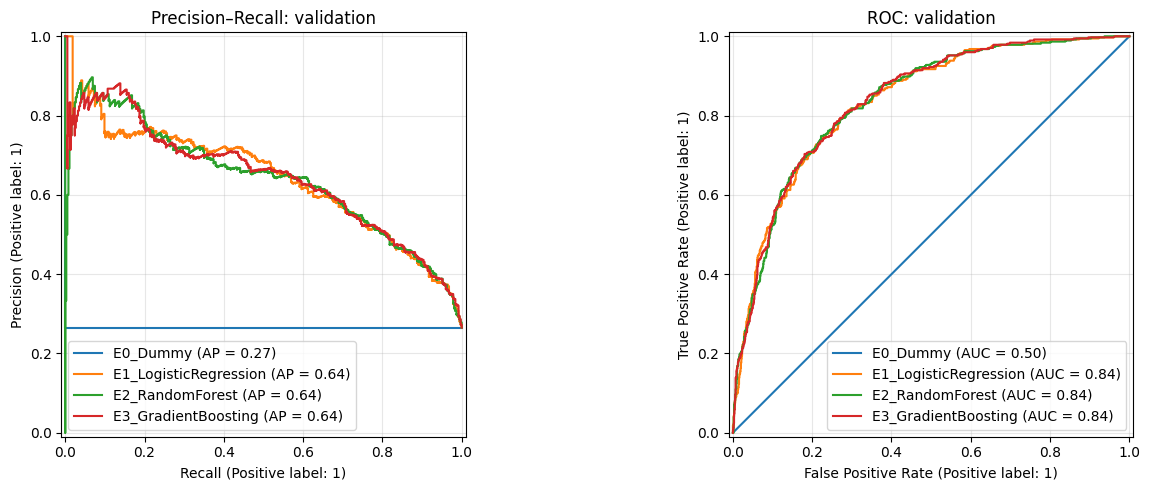

In [18]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    PrecisionRecallDisplay,
    RocCurveDisplay,
)

fig_part2, axes_part2 = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 5),
)

for run_id in EXPECTED_RUNS_PART2:
    probabilities = validation_probabilities_part2[run_id]

    PrecisionRecallDisplay.from_predictions(
        y_val_part2,
        probabilities,
        name=run_id,
        ax=axes_part2[0],
    )

    RocCurveDisplay.from_predictions(
        y_val_part2,
        probabilities,
        name=run_id,
        ax=axes_part2[1],
    )

axes_part2[0].set_title("Precision–Recall: validation")
axes_part2[1].set_title("ROC: validation")

for ax in axes_part2:
    ax.grid(alpha=0.3)

fig_part2.tight_layout()

fig_part2.savefig(
    ARTIFACTS_PART2 / "validation_comparison_curves.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()

### Итоговая оценка выбранной модели

На holdout оценивается только модель, выбранная по validation AP.
Дополнительное обучение или подбор параметров не выполняются.

Передаваемый экземпляр модели обучен на train — 4 225 клиентах.
На train + validation модель не переобучается, чтобы сохранить
соответствие между оценённым и передаваемым экземпляром.

Оговорка: состав holdout совпадает с выборкой, уже использованной
в предварительном эксперименте части 1. Поэтому результат
не является новой полностью независимой слепой проверкой.
Также совпадающие профили между выборками сохранены и описаны
в результатах валидации.

In [19]:
selected_classes_part2 = (
    selected_model_part2
    .named_steps["classifier"]
    .classes_
)

positive_class_positions_part2 = np.flatnonzero(
    selected_classes_part2 == 1
)

if len(positive_class_positions_part2) != 1:
    raise ValueError("Не удалось определить положительный класс.")

positive_class_position_part2 = int(
    positive_class_positions_part2[0]
)

# Применяем уже обученную и выбранную модель.
holdout_probabilities_part2 = (
    selected_model_part2
    .predict_proba(X_holdout_part2)[
        :, positive_class_position_part2
    ]
)

holdout_metrics_part2 = calculate_metrics_part2(
    y_holdout_part2,
    holdout_probabilities_part2,
    threshold=THRESHOLD_PART2,
)

holdout_results_part2 = pd.DataFrame([{
    "run_id": selected_run_id_part2,
    "dataset": "holdout",
    "clients": len(X_holdout_part2),
    "threshold": THRESHOLD_PART2,
    **holdout_metrics_part2,
}])

print("Итоговая оценка выбранной модели:")
display(holdout_results_part2.round(6))

# Сопоставление validation и holdout только для выбранной модели.
selected_validation_metrics_part2 = (
    experiment_results_part2[selected_run_id_part2]
)

selected_model_comparison_part2 = pd.DataFrame([
    {
        "dataset": "validation",
        **{
            metric: selected_validation_metrics_part2[metric]
            for metric in holdout_metrics_part2
        },
    },
    {
        "dataset": "holdout",
        **holdout_metrics_part2,
    },
])

print("\nValidation и holdout выбранной модели:")
display(selected_model_comparison_part2.round(6))

holdout_results_part2.to_csv(
    ARTIFACTS_PART2 / "holdout_metrics.csv",
    index=False,
    encoding="utf-8-sig",
)

# Экспорт данных для следующего участника.
# Порядок признаков, меток и вероятностей соответствует друг другу.
for dataset_name, features, target, probabilities in [
    (
        "validation",
        X_val_part2,
        y_val_part2,
        validation_probabilities_part2[selected_run_id_part2],
    ),
    (
        "holdout",
        X_holdout_part2,
        y_holdout_part2,
        holdout_probabilities_part2,
    ),
]:
    assert features.index.equals(target.index)
    assert len(features) == len(probabilities)

    predictions_table = features.copy()

    predictions_table.insert(
        0,
        "customerID",
        raw_part2.loc[
            features.index, "customerID"
        ].to_numpy(),
    )

    predictions_table["Churn_true"] = target.to_numpy()
    predictions_table["churn_probability"] = probabilities

    predictions_table["prediction_at_050"] = (
        np.asarray(probabilities) >= THRESHOLD_PART2
    ).astype(int)

    predictions_table.to_csv(
        ARTIFACTS_PART2 / f"{dataset_name}_predictions.csv",
        index=False,
        encoding="utf-8-sig",
    )

print("\nМетрики и предсказания сохранены.")
print("Модель не переобучалась, параметры не изменялись.")

Итоговая оценка выбранной модели:


,run_id,dataset,clients,threshold,AP,ROC_AUC,precision,recall,F1
0,E3_GradientBoosting,holdout,1409,0.5,0.665394,0.845128,0.666667,0.508021,0.576631



Validation и holdout выбранной модели:


,dataset,AP,ROC_AUC,precision,recall,F1
0,validation,0.643972,0.838531,0.664311,0.502674,0.572298
1,holdout,0.665394,0.845128,0.666667,0.508021,0.576631



Метрики и предсказания сохранены.
Модель не переобучалась, параметры не изменялись.


## Сохранение результатов и передача команде

Сохраняется выбранный pipeline Gradient Boosting:
подготовка признаков и классификатор в одном объекте.

Модель принимает таблицу из 19 признаков.
TotalCharges должен быть числовым: обработка исходных пустых
значений выполнена до обучения и не входит в сохранённый pipeline.

Положительный класс: 1 — клиент ушёл.
Порог бинарной классификации: 0,50.

Предварительные группы риска:
- low: p < 0,30;
- medium: 0,30 <= p < 0,60;
- high: p >= 0,60.

Границы риска не оптимизировались.
Отдельная калибровка вероятностей не выполнялась.

Участнику 3 передаются результаты проверок, разбиение
и предсказания с исходными признаками и истинными метками.

Участнику 4 передаются pipeline, метаданные, версии зависимостей
и пример входных данных.

Трекинг этой реализации выполняется через CSV/JSON:

In [20]:
import joblib
import matplotlib

MODEL_VERSION_PART2 = "churn-gb-1.0.0"

RISK_THRESHOLDS_PART2 = {
    "medium_min": 0.30,
    "high_min": 0.60,
}

model_path_part2 = ARTIFACTS_PART2 / "churn_pipeline.joblib"

joblib.dump(
    selected_model_part2,
    model_path_part2,
)

versions_part2 = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "joblib": joblib.__version__,
    "matplotlib": matplotlib.__version__,
}

metadata_part2 = {
    "model_version": MODEL_VERSION_PART2,
    "selected_run_id": selected_run_id_part2,
    "classifier": type(
        selected_model_part2.named_steps["classifier"]
    ).__name__,
    "classifier_parameters": (
        selected_model_part2
        .named_steps["classifier"]
        .get_params(deep=False)
    ),
    "features": FEATURE_COLUMNS_PART2,
    "numeric_features": NUMERIC_FEATURES_PART2,
    "categorical_features": CATEGORICAL_FEATURES_PART2,
    "target_mapping": {"No": 0, "Yes": 1},
    "positive_class": 1,
    "classification_threshold": THRESHOLD_PART2,
    "risk_thresholds": RISK_THRESHOLDS_PART2,
    "risk_thresholds_optimized": False,
    "probability_calibration_performed": False,
    "selection_dataset": "validation",
    "selection_metric": "average_precision",
    "validation_metrics": {
        metric: float(
            experiment_results_part2[
                selected_run_id_part2
            ][metric]
        )
        for metric in holdout_metrics_part2
    },
    "holdout_metrics": holdout_metrics_part2,
    "split_seed": SEED_PART2,
    "split_sizes": {
        name: len(indices)
        for name, indices in split_indices_part2.items()
    },
    "data_sha256": data_sha256_part2,
    "trained_on": "train_only",
    "versions": versions_part2,
    "input_preprocessing_note": (
        "TotalCharges must be numeric. In source CSV, empty "
        "TotalCharges was replaced with 0 only when tenure=0. "
        "This CSV cleaning is not included in the saved pipeline."
    ),
    "evaluation_notes": [
        "Holdout was previously examined in part 1.",
        "Matching profiles across splits were retained and counted.",
        "One fixed split; no statistical significance test.",
        "No hyperparameter search.",
    ],
}

with open(
    ARTIFACTS_PART2 / "model_metadata.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        metadata_part2,
        file,
        ensure_ascii=False,
        indent=2,
    )

requirements_part2 = "\n".join(
    f"{package}=={version}"
    for package, version in versions_part2.items()
    if package != "python"
) + "\n"

(ARTIFACTS_PART2 / "requirements.txt").write_text(
    requirements_part2,
    encoding="utf-8",
)

# Пример входа: только признаки, без ID и истинной метки.
example_input_part2 = json.loads(
    X_val_part2.iloc[0].to_json()
)

with open(
    ARTIFACTS_PART2 / "example_input.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        example_input_part2,
        file,
        ensure_ascii=False,
        indent=2,
    )

print("Сохранённая модель:", selected_run_id_part2)
print("Версия модели:", MODEL_VERSION_PART2)
print("Размер файла модели:", model_path_part2.stat().st_size, "байт")

print("\nВерсии среды:")
display(
    pd.Series(
        versions_part2,
        name="version",
    ).to_frame()
)

Сохранённая модель: E3_GradientBoosting
Версия модели: churn-gb-1.0.0
Размер файла модели: 164388 байт

Версии среды:


,version
python,3.13.18
numpy,2.4.6
pandas,2.2.3
scikit-learn,1.6.1
joblib,1.6.0
matplotlib,3.10.0


In [21]:
# Загружаем только что сохранённый нами файл.
loaded_model_part2 = joblib.load(model_path_part2)

loaded_classes_part2 = (
    loaded_model_part2
    .named_steps["classifier"]
    .classes_
)

loaded_positive_position_part2 = int(
    np.flatnonzero(loaded_classes_part2 == 1)[0]
)

loaded_probabilities_part2 = (
    loaded_model_part2
    .predict_proba(X_holdout_part2)[
        :, loaded_positive_position_part2
    ]
)

np.testing.assert_allclose(
    loaded_probabilities_part2,
    holdout_probabilities_part2,
    rtol=0,
    atol=1e-12,
)

max_difference_part2 = float(
    np.max(
        np.abs(
            loaded_probabilities_part2
            - holdout_probabilities_part2
        )
    )
)

print("Проверка сохранения и загрузки: PASS")
print("Сравнено прогнозов:", len(loaded_probabilities_part2))
print("Максимальная разница вероятностей:", max_difference_part2)

Проверка сохранения и загрузки: PASS
Сравнено прогнозов: 1409
Максимальная разница вероятностей: 0.0


In [22]:
import zipfile

# Объединяем проверки с одинаковой структурой.
validation_summary_part2 = pd.concat(
    [
        basic_checks_part2[["Проверка", "Нарушений", "Статус"]],
        category_checks_part2.rename(
            columns={"Колонка": "Проверка"}
        )[["Проверка", "Нарушений", "Статус"]].assign(
            Проверка=lambda table: "Категория: " + table["Проверка"]
        ),
        range_checks_part2[["Проверка", "Нарушений", "Статус"]],
        consistency_checks_part2[
            ["Проверка", "Нарушений", "Статус"]
        ],
    ],
    ignore_index=True,
)

validation_summary_part2.to_csv(
    ARTIFACTS_PART2 / "validation_checks_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

# Пропуски и совпадающие профили описаны отдельно:
# отсутствие FAIL не означает отсутствие найденных проблем.
handoff_text_part2 = f"""# Передача результатов части 2

Выбранный запуск: {selected_run_id_part2}
Версия модели: {MODEL_VERSION_PART2}
Обучение: только train, {len(X_train_part2)} клиентов.
Выбор модели: максимум AP на validation.

## Данные
Исходный CSV SHA256: {data_sha256_part2}
11 пустых TotalCharges при tenure=0 заменены нулём.
Совпадающие профили разных клиентов сохранены.
Подробности: cleaning_decisions.csv, duplicate_summary.csv,
profile_overlap.csv и остальные отчёты проверок.

## Участнику 3
validation_predictions.csv и holdout_predictions.csv содержат
признаки, ID, истинную метку и вероятность выбранной модели.
Для исследования и настройки используйте validation.
Если holdout используется для настройки, его нельзя затем
представлять как независимую итоговую оценку.

## Участнику 4
churn_pipeline.joblib содержит подготовку признаков и модель.
model_metadata.json описывает вход, метрики и пороги.
example_input.json — пример 19 входных признаков.
TotalCharges на входе должен быть числовым.
Очистка исходного CSV не входит в pipeline.
Предварительные границы риска: 0.30 и 0.60.
Калибровка и оптимизация границ не выполнялись.

## Воспроизводимость
Зависимости: requirements.txt.
Версия Python указана в model_metadata.json.
Время обучения зависит от среды.
Joblib-файл следует загружать только из доверенного источника.

## Реализованный стек
pandas-проверки; CSV/JSON-трекинг.
MLflow и Great Expectations не использованы.

## Ограничения оценки
Holdout уже просмотрен в части 1.
Совпадения профилей между выборками задокументированы.
Сравнивались три фиксированные конфигурации на одном разбиении.
Статистическая значимость различий не проверялась.
"""

(ARTIFACTS_PART2 / "README_part2.md").write_text(
    handoff_text_part2,
    encoding="utf-8",
)

required_artifacts_part2 = [
    "validation_checks_summary.csv",
    "missing_values_summary.csv",
    "numeric_conversion_checks.csv",
    "duplicate_summary.csv",
    "cleaning_decisions.csv",
    "split_manifest.csv",
    "split_summary.csv",
    "profile_overlap.csv",
    "experiment_parameters.json",
    "experiments_comparison.csv",
    "model_selection.json",
    "validation_comparison_curves.png",
    "holdout_metrics.csv",
    "validation_predictions.csv",
    "holdout_predictions.csv",
    "churn_pipeline.joblib",
    "model_metadata.json",
    "requirements.txt",
    "example_input.json",
    "README_part2.md",
]

missing_artifacts_part2 = [
    filename
    for filename in required_artifacts_part2
    if not (ARTIFACTS_PART2 / filename).is_file()
    or (ARTIFACTS_PART2 / filename).stat().st_size == 0
]

if missing_artifacts_part2:
    raise FileNotFoundError(
        f"Отсутствуют или пусты артефакты: {missing_artifacts_part2}"
    )

archive_path_part2 = (
    ARTIFACTS_PART2.parent / "churn_part2_artifacts.zip"
)

artifact_files_part2 = sorted(
    path
    for path in ARTIFACTS_PART2.iterdir()
    if path.is_file()
)

with zipfile.ZipFile(
    archive_path_part2,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
) as archive:
    for artifact_path in artifact_files_part2:
        archive.write(
            artifact_path,
            arcname=artifact_path.name,
        )

with zipfile.ZipFile(archive_path_part2, "r") as archive:
    damaged_file_part2 = archive.testzip()

if damaged_file_part2 is not None:
    raise ValueError(
        f"Повреждён файл в архиве: {damaged_file_part2}"
    )

print("Проверка обязательных артефактов: PASS")
print("Проверка архива: PASS")
print("Файлов в архиве:", len(artifact_files_part2))
print("Размер архива:", archive_path_part2.stat().st_size, "байт")

Проверка обязательных артефактов: PASS
Проверка архива: PASS
Файлов в архиве: 28
Размер архива: 347527 байт
